# EDA được kiểm chứng trên snapshot lịch sử

Ngày 07/11/2026. Đọc dữ liệu đã tổng hợp và hồ sơ đánh giá offline; không nạp lại CSV thô, không xác nhận coverage, không training/register/reload. Các output được thực thi bằng Python trong cùng tiến trình, không qua kernel Jupyter; có thể chạy lại từ đầu trong notebook. Không dùng dữ liệu mô phỏng để suy luận thị phần thực tế.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/daily_history.parquet').exists())
sys.path.insert(0, str(root))
evidence = root / 'docs/07-bao-cao-do-an/evidence/remediation-2026-11-07'
result = json.loads((evidence / 'baseline-evaluation.json').read_text(encoding='utf-8'))
path = root / 'data/daily_history.parquet'
saved_hash = next(v for k, v in result['source_sha256'].items() if k.replace(chr(92), '/') == 'data/daily_history.parquet')
assert hashlib.sha256(path.read_bytes()).hexdigest() == saved_hash
daily = pd.read_parquet(path)
print('rows:', len(daily), 'SKUs:', daily.sku.nunique(), 'days:', daily.date.nunique())
print('dates:', daily.date.min(), daily.date.max())
print('source fingerprint verified; snapshot read only')


rows: 49032 SKUs: 216 days: 227
dates: 2025-12-28 2026-08-11
source fingerprint verified; snapshot read only


In [2]:
print(daily.daily_demand.describe().to_string())
print('median:', daily.daily_demand.median())
print('zero_fraction:', daily.daily_demand.eq(0).mean())
print('duplicate_sku_date:', daily.duplicated(['sku', 'date']).sum())
print('missing_by_column:')
print(daily.isna().sum().to_string())


count    49032.000000
mean         0.117434
std          1.621201
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        232.000000
median: 0.0
zero_fraction: 0.9549069995105237
duplicate_sku_date: 0
missing_by_column:
sku                   0
date                  0
daily_demand          0
daily_revenue         0
avg_unit_price        0
total_discount        0
order_count           0
product_name          0
category          49032


**Diễn giải:** mean và median khác nhau lớn, phần lớn ô bằng 0. Snapshot được tạo sau zero-fill, nên tỷ lệ 0 chưa phải tỷ lệ ngày không bán đã được nguồn chứng nhận. Cột category thiếu toàn bộ; giá/doanh thu của nguồn lịch sử không mang đủ thông tin để diễn giải tài chính. Không có khóa SKU/ngày trùng trong snapshot không chứng minh CSV gốc chưa từng có dòng trùng.

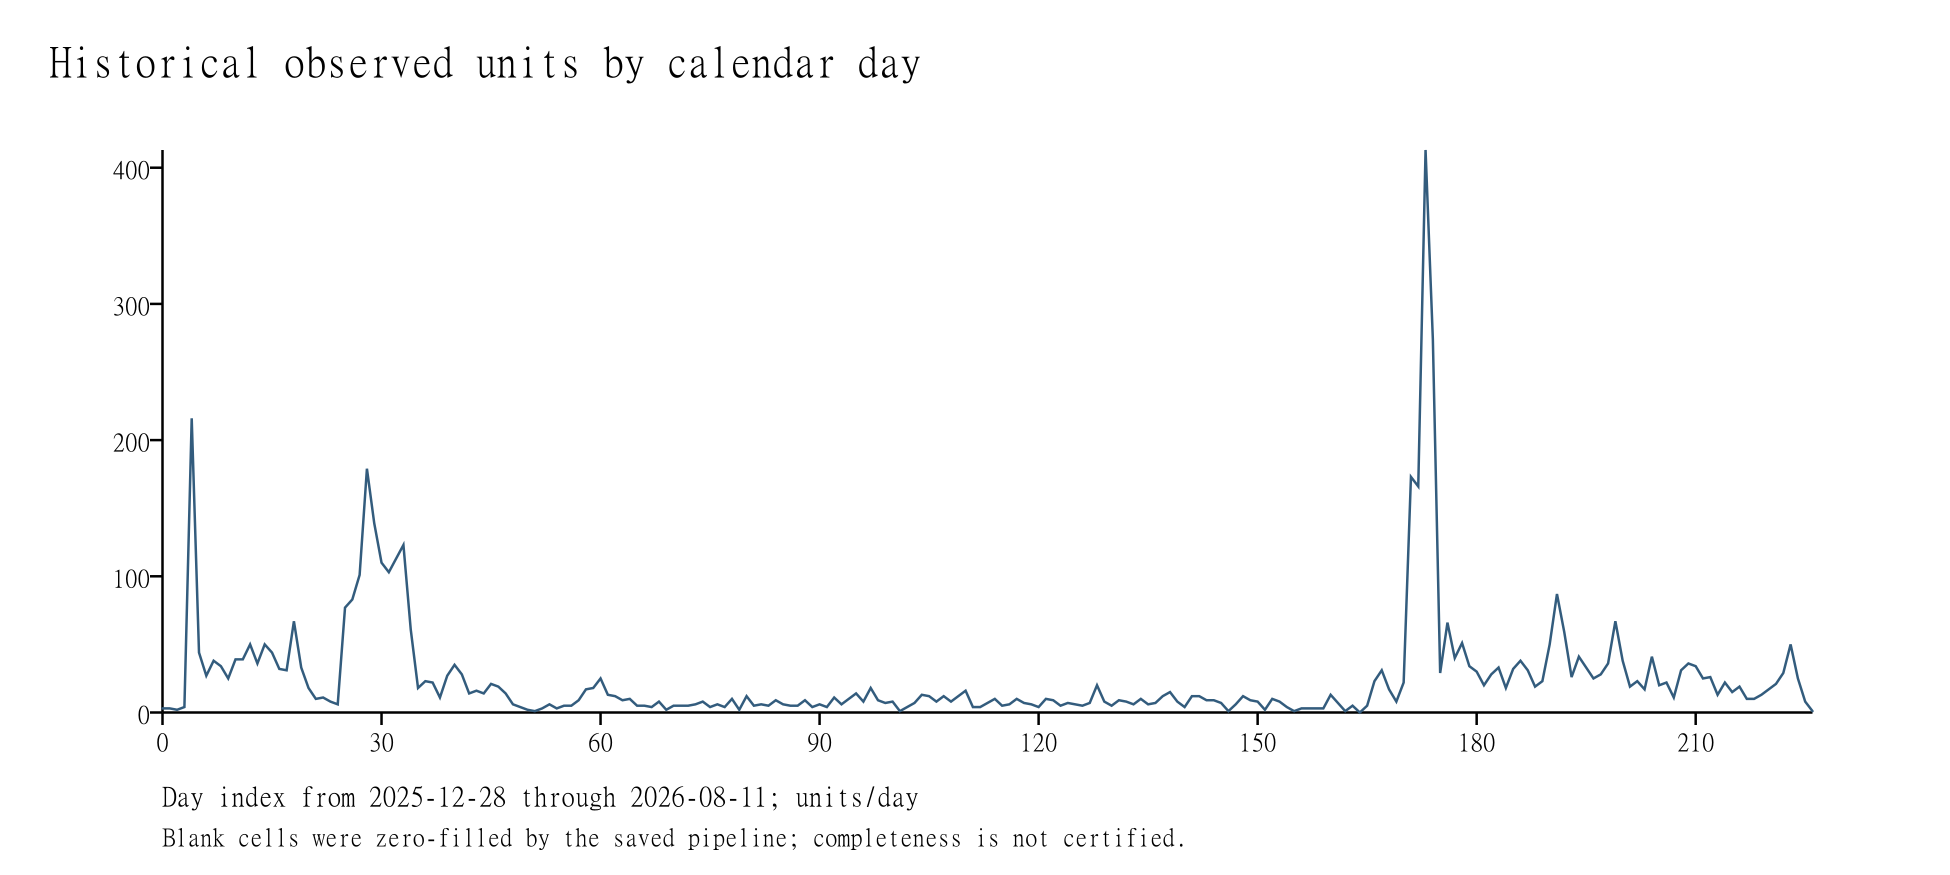

In [3]:
display_png(evidence / 'historical-eda.png')


                model  pooled_wape  scored_rows  expected_rows
         naive_legacy       123.95         8484           9072
seasonal_naive_legacy       153.88         8484           9072
moving_average_legacy       124.41         8484           9072
             naive_v2       130.87         8484           9072
    seasonal_naive_v2       146.40         8484           9072
    moving_average_v2       121.15         8484           9072
      zero_diagnostic       100.00         8484           9072
selected on development: moving_average_v2
holdout metrics: {'mae': 0.1157, 'rmse': 0.4289, 'mape': 8.56, 'wape': 142.19, 'r2': 0.2101, 'bias': 59.56, 'mean_fold_wape': 142.19, 'defined_wape_folds': 1, 'undefined_wape_folds': 0, 'scored_rows': 3010}


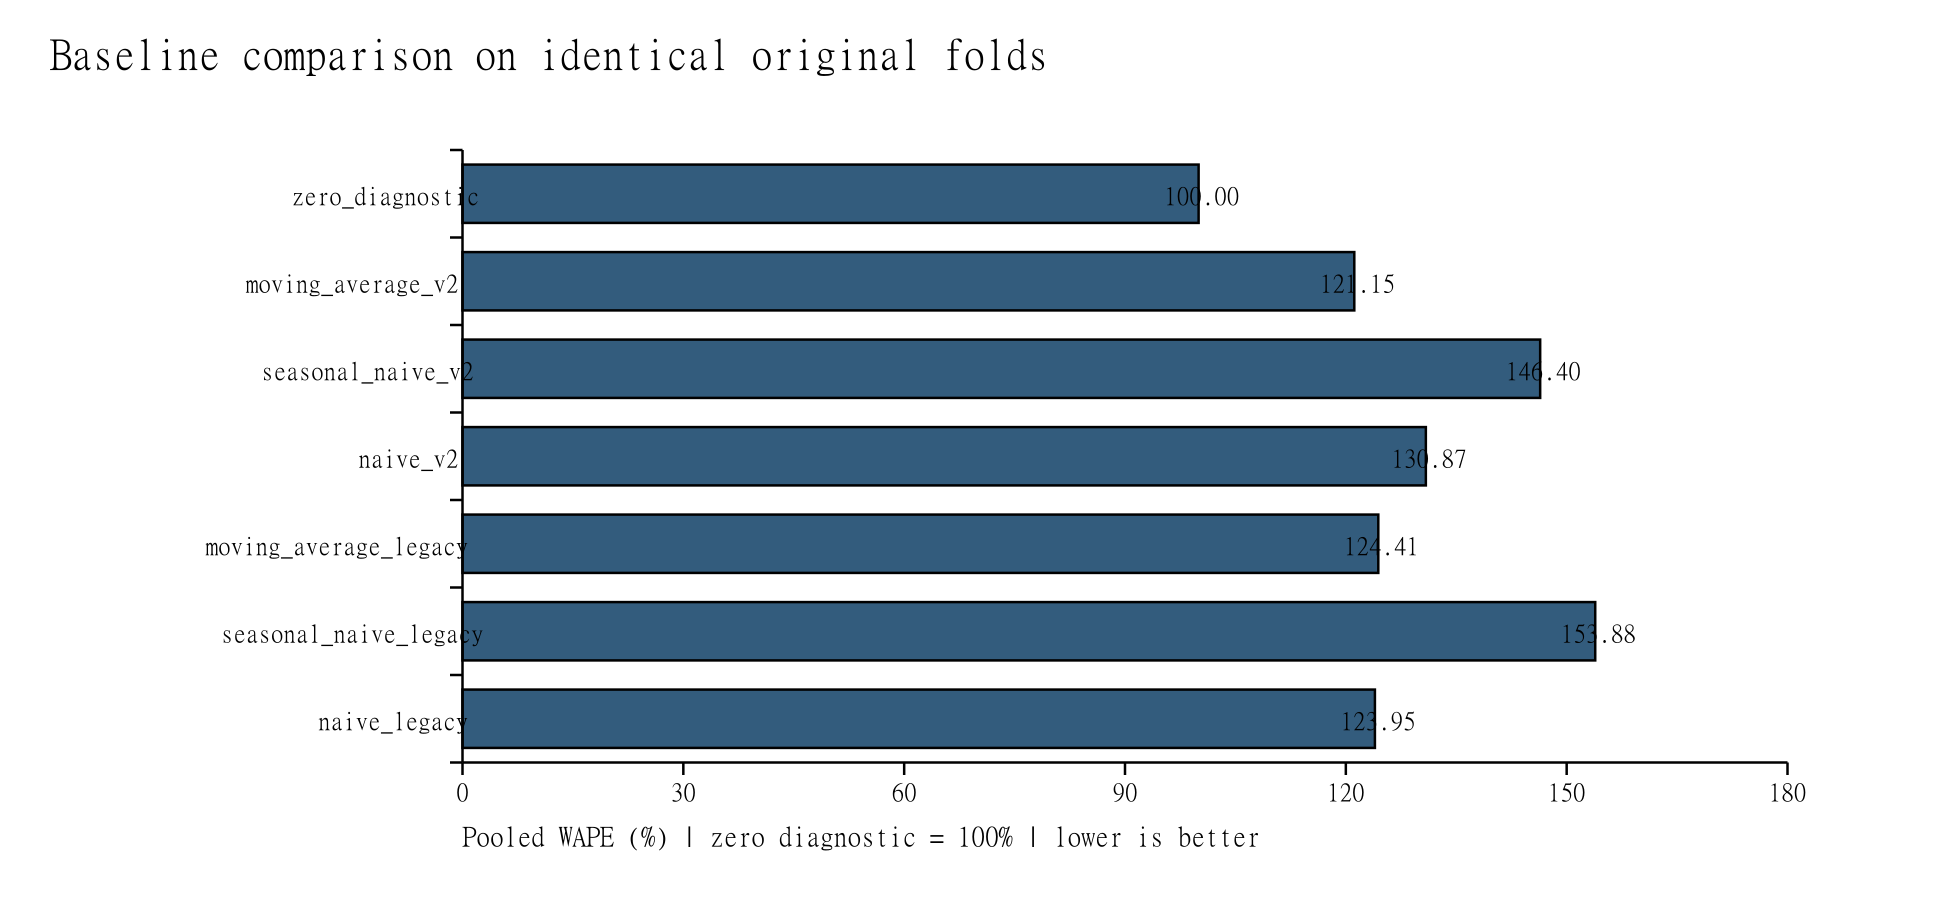

In [4]:
rows = [{'model': name, 'pooled_wape': value['pooled_metrics']['wape'],
         'scored_rows': value['scored_rows'], 'expected_rows': value['expected_rows']}
        for name, value in result['same_original_folds_before_after'].items()]
print(pd.DataFrame(rows).to_string(index=False))
print('selected on development:', result['holdout']['selected_using_development_only'])
name = result['holdout']['selected_using_development_only']
print('holdout metrics:', result['holdout']['scores'][name]['pooled_metrics'])
display_png(evidence / 'baseline-wape.png')


**Diễn giải:** Moving Average cải thiện WAPE gộp ở ba fold gốc nhưng holdout vẫn kém mốc dự báo 0. Sửa đúng công thức không bảo đảm sai số giảm cho mọi mô hình. Chọn model chỉ dùng các fold phát triển; không chọn lại sau khi xem holdout. Không suy ra hiệu quả nhập hàng hoặc tính đại diện thị trường.

In [5]:
from ml.training.metrics import calculate_all_metrics
print(json.dumps(calculate_all_metrics([0, 0], [4, 4]), allow_nan=False))
assert result['deployment_artifacts_unchanged'] is True
print('WAPE/bias undefined => null; original deployment artifact hashes unchanged during evaluation')


{"mae": 4.0, "rmse": 4.0, "mape": 400.0, "wape": null, "r2": 0.0, "bias": null}
WAPE/bias undefined => null; original deployment artifact hashes unchanged during evaluation
